# Cloud Data Warehouses (BigQuery Sandbox)

**Cloud data warehouses** store terabytes to petabytes of analytical data and answer SQL queries in seconds by spreading the work over many machines. The main systems are **Google BigQuery**, **Snowflake**, **Amazon Redshift** and **Databricks SQL**. They share the ideas of Lesson 08 (columnar storage) and Lesson 15 (star schemas), plus **separation of storage and compute** and **pay-per-use** pricing.

**After this lesson you can:**

1. Explain the architecture and pricing models of cloud warehouses.
2. Estimate query cost from the bytes a query scans.
3. Reduce cost with column selection, partitioning and clustering.
4. Start with BigQuery for free (Sandbox) and write BigQuery SQL.

All experiments run locally with DuckDB and Parquet, so the lesson needs no cloud account. The BigQuery statements at the end show the same ideas in the cloud.

In [1]:
import tempfile
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

WORK = Path(tempfile.mkdtemp())
con = duckdb.connect()
_ = con.execute("SET enable_progress_bar = false")   # no progress widget in the notebook output

## 1. Architecture

| Idea | Meaning |
| :--- | :--- |
| **separation of storage and compute** | data lives in cheap object storage; compute clusters start, scale and stop independently |
| **columnar, compressed storage** | queries read only the columns they need |
| **massively parallel processing (MPP)** | one query runs on hundreds of workers |
| **serverless** (BigQuery) | no cluster to manage; you pay per query or for reserved capacity |

| System | Pricing model (simplified) | Free option |
| :--- | :--- | :--- |
| BigQuery | on-demand: per TiB **scanned**; or reserved slots | Sandbox: 10 GB storage and 1 TiB of queries per month, no credit card |
| Snowflake | credits per second of warehouse runtime | 30-day trial |
| Redshift Serverless | per RPU-hour | trial credit |
| Databricks SQL | DBUs per hour | Free Edition |

Prices change; check the vendor's pricing page. With on-demand BigQuery, the **bytes scanned** decide the bill, so every design choice in this lesson aims to scan fewer bytes.

## 2. A Warehouse Table (Synthetic Data)

The cell creates a synthetic **page-view event** table with 4 million rows and 9 columns, the kind of table a web analytics team stores.

In [2]:
rng = np.random.default_rng(0)
n = 4_000_000
events = pd.DataFrame({
    "event_time": pd.Timestamp("2025-01-01") + pd.to_timedelta(rng.integers(0, 365 * 86400, n), unit="s"),
    "user_id": rng.integers(1, 2_000_000, n),
    "country": pd.Categorical(rng.choice(["TR", "DE", "US", "BR", "IN", "GB", "FR", "JP"], n)),   # categorical: low memory
    "device": pd.Categorical(rng.choice(["mobile", "desktop", "tablet"], n, p=[.6, .33, .07])),
    "page": pd.Categorical.from_codes(rng.integers(0, 5000, n), [f"/product/{i}" for i in range(5000)]),
    "referrer": pd.Categorical(rng.choice(["google", "direct", "newsletter", "social", "ads"], n)),
    "session_seconds": rng.exponential(120, n).round(1),
    "revenue": np.where(rng.random(n) < 0.02, rng.gamma(2, 30, n).round(2), 0.0),
})
events["event_date"] = events["event_time"].dt.normalize()     # datetime64, not Python date objects (much smaller)
flat = WORK / "events_flat.parquet"
events.to_parquet(flat, index=False, row_group_size=500_000)
print(f"{n:,} rows, {flat.stat().st_size / 1e6:.0f} MB as Parquet")

4,000,000 rows, 77 MB as Parquet


## 3. Estimate the Bytes a Query Scans

BigQuery bills the **logical (uncompressed) bytes** of the columns a query reads, in the partitions it reads. Parquet metadata stores the uncompressed size of every column in every row group, so the cell can estimate the bill of a query without running it, similar to BigQuery's **dry run**.

In [3]:
PRICE_PER_TIB = 6.25          # BigQuery on-demand list price in USD per TiB scanned (check the current price)

def scanned_bytes(paths, columns) -> int:
    total = 0
    for path in paths:
        meta = pq.ParquetFile(path).metadata
        for rg in range(meta.num_row_groups):
            for c in range(meta.num_columns):
                col = meta.row_group(rg).column(c)
                if col.path_in_schema in columns:
                    total += col.total_uncompressed_size
    return total

all_cols = list(events.columns)
scenarios = {
    "SELECT * (all columns)": scanned_bytes([flat], all_cols),
    "SELECT country, revenue": scanned_bytes([flat], ["country", "revenue"]),
}
for name, b in scenarios.items():
    print(f"{name:<26} {b / 1e9:6.3f} GB -> ${b / 2**40 * PRICE_PER_TIB:.5f} per query")

SELECT * (all columns)      0.093 GB -> $0.00053 per query
SELECT country, revenue     0.003 GB -> $0.00002 per query


The amounts are small for 4 million rows, but warehouses hold tables that are thousands of times larger, and dashboards run the same query hundreds of times a day. Selecting two columns instead of `*` cuts the scan by the same factor, at any scale.

## 4. Partitioning and Clustering

- **Partitioning** splits a table into separate parts, usually by date. A filter on the partition column (`WHERE event_date = ...`) reads only the matching partitions (**partition pruning**).
- **Clustering** sorts the data inside each partition by some columns (for example `country`). Blocks store min/max statistics, so a filter on a clustered column skips blocks.

The cell writes the table partitioned by month and clustered (sorted) by country, then compares the bytes scanned for a query on one week and one country.

In [4]:
part_dir = WORK / "events_partitioned"
con.sql(f"""COPY (SELECT *, strftime(event_time, '%Y-%m') AS month FROM '{flat}' ORDER BY month, country)
            TO '{part_dir}' (FORMAT parquet, PARTITION_BY (month), ROW_GROUP_SIZE 100000, OVERWRITE_OR_IGNORE)""")
query_cols = ["event_date", "country", "revenue", "device"]

def pruned_bytes(files, country=None):
    total = 0
    for path in files:
        pf = pq.ParquetFile(path)
        names = pf.schema_arrow.names
        for rg in range(pf.metadata.num_row_groups):
            g = pf.metadata.row_group(rg)
            if country is not None:
                st = g.column(names.index("country")).statistics
                if not (st.min <= country <= st.max):
                    continue                                  # block skipped by its min/max statistics
            total += sum(g.column(names.index(c)).total_uncompressed_size for c in query_cols)
    return total

march = sorted(part_dir.glob("month=2025-03/*.parquet"))
costs = {
    "flat table, SELECT *": scanned_bytes([flat], all_cols),
    "flat table, 4 columns": scanned_bytes([flat], query_cols),
    "partitioned by month": pruned_bytes(march),
    "partitioned + clustered by country": pruned_bytes(march, country="TR"),
}
week = con.sql(f"""SELECT device, round(sum(revenue)) AS revenue, count(*) AS views
                   FROM read_parquet('{part_dir}/*/*.parquet', hive_partitioning = true)
                   WHERE month = '2025-03' AND event_date BETWEEN DATE '2025-03-03' AND DATE '2025-03-09' AND country = 'TR'
                   GROUP BY ALL ORDER BY revenue DESC""").df()
print(week.to_string(index=False))
for k, v in costs.items():
    print(f"{k:<36} {v / 1e6:9.1f} MB")

 device  revenue  views
 mobile   5916.0   5565
desktop   2578.0   3173
 tablet   1092.0    696
flat table, SELECT *                      92.6 MB
flat table, 4 columns                      8.7 MB
partitioned by month                       0.7 MB
partitioned + clustered by country         0.3 MB


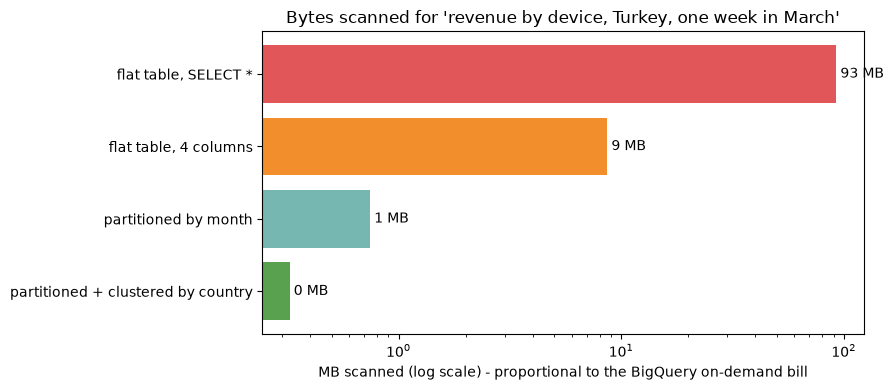

reduction from SELECT * on the flat table: 285x


In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
names = list(costs)
ax.barh(names[::-1], [costs[k] / 1e6 for k in names][::-1], color=["#59A14F", "#76B7B2", "#F28E2B", "#E15759"])
for i, k in enumerate(names[::-1]):
    ax.text(costs[k] / 1e6, i, f" {costs[k] / 1e6:,.0f} MB", va="center")
ax.set(xscale="log", title="Bytes scanned for 'revenue by device, Turkey, one week in March'",
       xlabel="MB scanned (log scale) - proportional to the BigQuery on-demand bill")
plt.tight_layout()
plt.show()
print(f"reduction from SELECT * on the flat table: {costs[names[0]] / costs[names[-1]]:.0f}x")

The same answer costs a small fraction of the original scan. In a real warehouse, the partition would be one day instead of one month, and the effect is even larger.

## 5. BigQuery in Practice (Free Sandbox)

1. Open the BigQuery console with a Google account; the **Sandbox** needs no credit card.
2. Public datasets (`bigquery-public-data`) include real data such as GitHub activity, Stack Overflow and NOAA weather.
3. The query editor shows the estimated bytes **before** you run a query (dry run). Always check it.

BigQuery statements for the ideas above (shown, not executed here):

```sql
-- partitioned and clustered table
CREATE TABLE analytics.page_views
PARTITION BY DATE(event_time)
CLUSTER BY country, device
OPTIONS (require_partition_filter = TRUE)       -- refuse queries that would scan every partition
AS SELECT * FROM staging.page_views_raw;

-- a cheap query: few columns, one week of partitions
SELECT device, SUM(revenue) AS revenue
FROM analytics.page_views
WHERE DATE(event_time) BETWEEN '2025-03-03' AND '2025-03-09' AND country = 'TR'
GROUP BY device;

-- a real public dataset
SELECT name, SUM(number) AS babies
FROM `bigquery-public-data.usa_names.usa_1910_current`
WHERE year >= 2000 GROUP BY name ORDER BY babies DESC LIMIT 10;
```

From Python, the `google-cloud-bigquery` client runs the same SQL and returns a pandas DataFrame (`client.query(sql).to_dataframe()`); `QueryJobConfig(dry_run=True)` returns the bytes a query would scan.

*Insight: In a pay-per-scan warehouse, the query design is the bill. Select only the columns you need, partition large tables by date, cluster them by common filters, require partition filters, and check the dry-run estimate before running a query on a big table.*

## Real-World Use Case or Analogy

A cloud warehouse with on-demand pricing is like a **library that charges per page you read**. Asking the librarian for "all books" is expensive; asking for "page 3 of the March 2025 issues, Turkish section" is cheap. Partitions are the shelves by month, clustering is the alphabetical order on each shelf.

Companies have received surprise bills because a dashboard ran `SELECT *` on an unpartitioned table every few minutes. Analytics engineers (M11) spend much of their time designing tables and dbt models so that common queries scan as little as possible.